<a href="https://colab.research.google.com/github/11249a290-glitch/11249A290/blob/main/N_GRAM_SMOOTHING_TECHNIQUES.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Common setup used across all experiments
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
from nltk import bigrams, trigrams, FreqDist
from nltk.tokenize import word_tokenize
corpus = """I am learning natural language processing.
I am learning smoothing techniques for NLP.
Natural language processing is fun to learn."""
tokens = word_tokenize(corpus.lower())
print("Tokens:", tokens)
print("Total tokens (N):", len(tokens))

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...


Tokens: ['i', 'am', 'learning', 'natural', 'language', 'processing', '.', 'i', 'am', 'learning', 'smoothing', 'techniques', 'for', 'nlp', '.', 'natural', 'language', 'processing', 'is', 'fun', 'to', 'learn', '.']
Total tokens (N): 23


[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


In [ ]:
import nltk
from nltk import FreqDist, bigrams
from nltk.tokenize import word_tokenize
#11249A290
corpus = """Natural language processing empowers computers to analyze and understand human text.
Smoothing techniques like Laplace smoothing solve the data sparsity problem by reallocating
probability mass to unseen n-grams. Without smoothing, zero counts ruin language model evaluation
and perplexity calculations completely."""
tokens = word_tokenize(corpus.lower())
unigram_freq = FreqDist(tokens)
bigram_freq = FreqDist(bigrams(tokens))
vocab_size = len(unigram_freq)
def add1_prob(w1, w2):
  numerator = bigram_freq[(w1, w2)] + 1
  denominator = unigram_freq[w1] + vocab_size
  return numerator / denominator
test_pairs = [("language", "processing"), ("laplace", "smoothing"), ("zero", "counts"), ("human", "processing")]

print(f"Total tokens = {len(tokens)}")
print(f"Vocabulary size (V) = {vocab_size}\n")
print(f"{'Bigram': <25}{'Count': <8}{'P(w2|w1) Add-1':<15}")
for w1, w2 in test_pairs:
  p = add1_prob(w1, w2)
  print(f"P({w2}|{w1}){' ' * (15 - len(w1) - len(w2))}{bigram_freq[(w1, w2)]:<8}{p:.5f}")

LookupError: 
**********************************************************************
  Resource [93mpunkt_tab[0m not found.
  Please use the NLTK Downloader to obtain the resource:

  [31m>>> import nltk
  >>> nltk.download('punkt_tab')
  [0m
  For more information see: https://www.nltk.org/data.html

  Attempted to load [93mtokenizers/punkt_tab/english/[0m

  Searched in:
    - '/root/nltk_data'
    - '/usr/nltk_data'
    - '/usr/share/nltk_data'
    - '/usr/lib/nltk_data'
    - '/usr/share/nltk_data'
    - '/usr/local/share/nltk_data'
    - '/usr/lib/nltk_data'
    - '/usr/local/lib/nltk_data'
**********************************************************************


In [ ]:
def addk_prob(w1, w2, k):
    """P(w2 | w1) using Add-k smoothing (0 < k <= 1 typically)"""
    numerator   = bigram_freq[(w1, w2)] + k
    denominator = unigram_freq[w1] + (k * vocab_size)           #11249A290
    return numerator / denominator
k_values = [0.01, 0.1, 0.5, 1.0]
print(f"{'Bigram':<20}", end="")
for k in k_values:
    print(f"k={k:<10}", end="")
print()
for w1, w2 in test_pairs:
    print(f"P({w2}|{w1}){' '*(20-6-len(w1)-len(w2))}", end="")
    for k in k_values:
        p = addk_prob(w1, w2, k)
        print(f"{p:<12.5f}", end="")
    print()

Bigram              k=0.01      k=0.1       k=0.5       k=1.0       
P(processing|language)0.42616     0.19298     0.07317     0.05128     
P(smoothing|laplace)0.73723     0.23404     0.07692     0.05263     
P(counts|zero)    0.73723     0.23404     0.07692     0.05263     
P(processing|human)0.00730     0.02128     0.02564     0.02632     


In [ ]:
unigram_freq = FreqDist(tokens)
bigram_freq  = FreqDist(bigrams(tokens))
trigram_freq = FreqDist(trigrams(tokens))
N = len(tokens)

lambda1, lambda2, lambda3 = 0.1, 0.3, 0.6           #11249A290

def interpolated_prob(w1, w2, w3):
  """P(w3 | w1, w2) using linear interpolation of tri/bi/unigram MLEs"""
  p_uni = unigram_freq[w3] / N
  p_bi = (bigram_freq[(w2, w3)] / unigram_freq[w2]
              if unigram_freq[w2] > 0 else 0)

  p_tri = (trigram_freq[(w1, w2, w3)] / bigram_freq[(w1, w2)]
              if bigram_freq[(w1, w2)] > 0 else 0)

  return (lambda1 * p_uni) + (lambda2 * p_bi) + (lambda3 * p_tri)

test_triples = [("i", "am", "learning"),
                 ("am", "learning", "nlp"),
                 ("is", "fun", "to")]

print(f"lambda1={lambda1}, lambda2={lambda2}, lambda3={lambda3}\n")
for w1, w2, w3 in test_triples:
    p = interpolated_prob(w1, w2, w3)
    print(f"P({w3}|{w1},{w2}) [Interpolation] = {p:.5f}")

lambda1=0.1, lambda2=0.3, lambda3=0.6

P(learning|i,am) [Interpolation] = 0.00000
P(nlp|am,learning) [Interpolation] = 0.00000
P(to|is,fun) [Interpolation] = 0.00455


In [ ]:
alpha = 0.4
def stupid_backoff(w1, w2, w3):           #11249A290
  """P(w3 | w1, w2) using Stupid Backoff:
  trigram -> bigram -> unigram, discounted by alpha at each drop"""
  if trigram_freq[(w1, w2, w3)] > 0:
    return trigram_freq[(w1, w2, w3)] / bigram_freq[(w1, w2)]
  elif bigram_freq[(w2, w3)] > 0:
    return alpha * (bigram_freq[(w2, w3)] / unigram_freq[w2])
  else:
    return (alpha ** 2) * (unigram_freq[w3] / N)
print(f"alpha = {alpha}\n")
for w1, w2, w3 in test_triples:
  p = stupid_backoff(w1, w2, w3)
  level = ("trigram" if trigram_freq[(w1, w2, w3)] > 0 else
  "bigram"  if bigram_freq[(w2, w3)] > 0 else "unigram")
  print(f"P({w3}|{w1},{w2}) [Backoff -> {level:<8}] = {p:.5f}")

alpha = 0.4

P(learning|i,am) [Backoff -> unigram ] = 0.00000
P(nlp|am,learning) [Backoff -> unigram ] = 0.00000
P(to|is,fun) [Backoff -> unigram ] = 0.00727


In [ ]:
corpus = """Natural language processing empowers computers to analyze and understand human text.
Smoothing techniques like Laplace smoothing solve the data sparsity problem by reallocating
probability mass to unseen n-grams. Without smoothing, zero counts ruin language model evaluation
and perplexity calculations completely."""

tokens = word_tokenize(corpus.lower())
unigram_freq = FreqDist(tokens)
bigram_freq = FreqDist(bigrams(tokens))
trigram_freq = FreqDist(trigrams(tokens))               #11249A290
vocab_size = len(unigram_freq)


def add1_prob(w1, w2):
    return (bigram_freq[(w1, w2)] + 1) / (unigram_freq[w1] + vocab_size)

print(f"Total tokens = {len(tokens)}")
print(f"Vocabulary size (V) = {vocab_size}\n")

print(f"P(processing|language) Add-1 = {add1_prob('language', 'processing'):.5f}")

print(f"P(processing|human) Add-1 = {add1_prob('human', 'processing'):.5f}\n")

def add1_trigram_prob(w1, w2, w3):
    return (trigram_freq[(w1, w2, w3)] + 1) / (bigram_freq[(w1, w2)] + vocab_size)

print(f"Trigram P(processing|language, natural) Add-1 = {add1_trigram_prob('natural', 'language', 'processing'):.5f}")

Total tokens = 44
Vocabulary size (V) = 37

P(processing|language) Add-1 = 0.05128
P(processing|human) Add-1 = 0.02632

Trigram P(processing|language, natural) Add-1 = 0.05263


Bigram                   k=0.01      k=0.1       k=0.5       k=1.0       
P(processing|language)   0.42616     0.19298     0.07317     0.05128     
P(smoothing|laplace)     0.73723     0.23404     0.07692     0.05263     
P(counts|zero)           0.73723     0.23404     0.07692     0.05263     
P(processing|human)      0.00730     0.02128     0.02564     0.02632     


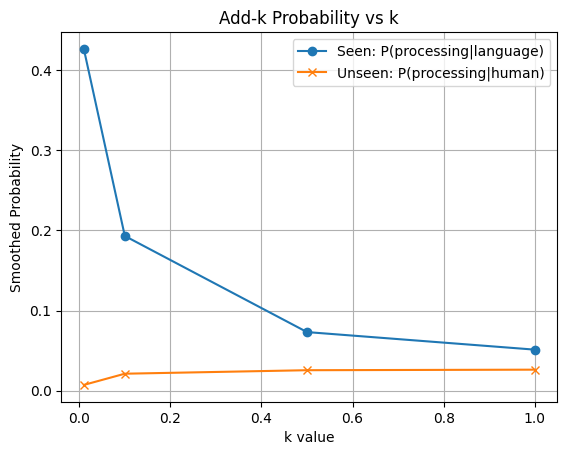

In [ ]:
import matplotlib.pyplot as plt
def addk_prob(w1, w2, k):
    return (bigram_freq[(w1, w2)] + k) / (unigram_freq[w1] + (k * vocab_size))
k_values = [0.01, 0.1, 0.5, 1.0]
test_pairs = [("language", "processing"), ("laplace", "smoothing"), ("zero", "counts"), ("human", "processing")]

print(f"{'Bigram':<25}", end="")
for k in k_values:
    print(f"k={k:<10}", end="")
print()                                        #11249A290
for w1, w2 in test_pairs:
    bigram_str = f"P({w2}|{w1})"
    print(f"{bigram_str:<25}", end="")
    for k in k_values:
        print(f"{addk_prob(w1, w2, k):<12.5f}", end="")
    print()

seen_probs = [addk_prob("language", "processing", k) for k in k_values]
unseen_probs = [addk_prob("human", "processing", k) for k in k_values]
plt.plot(k_values, seen_probs, label="Seen: P(processing|language)", marker='o')
plt.plot(k_values, unseen_probs, label="Unseen: P(processing|human)", marker='x')
plt.xlabel("k value")
plt.ylabel("Smoothed Probability")
plt.title("Add-k Probability vs k")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
N = len(tokens)

def interpolated_prob_detailed(w1, w2, w3, l1, l2, l3):
    p_uni = unigram_freq[w3] / N
    p_bi = bigram_freq[(w2, w3)] / unigram_freq[w2] if unigram_freq[w2] > 0 else 0
    p_tri = trigram_freq[(w1, w2, w3)] / bigram_freq[(w1, w2)] if bigram_freq[(w1, w2)] > 0 else 0
    total = (l1 * p_uni) + (l2 * p_bi) + (l3 * p_tri)
    return p_uni, p_bi, p_tri, total
test_triples = [("natural", "language", "processing"), ("without", "smoothing", "zero")]          #11249A290
# 1, 2 & 3. Comparing weights and printing individual components
for l1, l2, l3 in [(0.1, 0.3, 0.6), (0.6, 0.3, 0.1)]:
    print(f"\n--- Weights: l1={l1}, l2={l2}, l3={l3} ---")
    for w1, w2, w3 in test_triples:
        p_uni, p_bi, p_tri, total = interpolated_prob_detailed(w1, w2, w3, l1, l2, l3)
        print(f"P({w3}|{w1},{w2}): Total={total:.5f} [MLE Unigram={p_uni:.4f}, Bigram={p_bi:.4f}, Trigram={p_tri:.4f}]")


--- Weights: l1=0.1, l2=0.3, l3=0.6 ---
P(processing|natural,language): Total=0.75227 [MLE Unigram=0.0227, Bigram=0.5000, Trigram=1.0000]
P(zero|without,smoothing): Total=0.00227 [MLE Unigram=0.0227, Bigram=0.0000, Trigram=0.0000]

--- Weights: l1=0.6, l2=0.3, l3=0.1 ---
P(processing|natural,language): Total=0.26364 [MLE Unigram=0.0227, Bigram=0.5000, Trigram=1.0000]
P(zero|without,smoothing): Total=0.01364 [MLE Unigram=0.0227, Bigram=0.0000, Trigram=0.0000]


In [ ]:
alpha = 0.4
def stupid_backoff_with_level(w1, w2, w3, a=0.4):
    if trigram_freq[(w1, w2, w3)] > 0:
        return trigram_freq[(w1, w2, w3)] / bigram_freq[(w1, w2)], "trigram"
    elif bigram_freq[(w2, w3)] > 0:
        return a * (bigram_freq[(w2, w3)] / unigram_freq[w2]), "bigram"
    else:
        return (a ** 2) * (unigram_freq[w3] / N), "unigram"  #11249A290

test_triples = [("natural", "language", "processing"), ("like", "laplace", "smoothing"), ("without", "smoothing", "zero")]
print(f"{'Trigram':<35}{'Alpha=0.4':<15}{'Alpha=0.7':<15}{'Level':<10}")
for w1, w2, w3 in test_triples:
    p_04, lvl = stupid_backoff_with_level(w1, w2, w3, a=0.4)
    p_07, _ = stupid_backoff_with_level(w1, w2, w3, a=0.7)
    print(f"P({w3}|{w1},{w2}):{'' * (35-len(w1)-len(w2)-len(w3))}{p_04:<15.5f}{p_07:<15.5f}{lvl:<10}")

levels = [stupid_backoff_with_level(w1, w2, w3)[1] for w1, w2, w3 in test_triples]
print(f"\nTrigram resolved: {levels.count('trigram') / len(levels) * 100:.1f}%")
print(f"Bigram resolved: {levels.count('bigram') / len(levels) * 100:.1f}%")
print(f"Unigram resolved: {levels.count('unigram') / len(levels) * 100:.1f}%")

Trigram                            Alpha=0.4      Alpha=0.7      Level     
P(processing|natural,language):1.00000        1.00000        trigram   
P(smoothing|like,laplace):1.00000        1.00000        trigram   
P(zero|without,smoothing):0.00364        0.01114        unigram   

Trigram resolved: 66.7%
Bigram resolved: 0.0%
Unigram resolved: 33.3%


In [ ]:
import nltk
from nltk import word_tokenize, pos_tag
nltk.download('punkt')
nltk.download('averaged_perceptron_tagger')
nltk.download('averaged_perceptron_tagger_eng')   #11249A290
nltk.download('punkt_tab')
sentence = input("Enter a sentence: ")

tokens = word_tokenize(sentence)
print("\nTokens:", tokens)

tagged = pos_tag(tokens)
print("\nWord\t\tPoS Tag")
print("-" * 30)
for word, tag in tagged:
 print(f"{word}\t\t{tag}")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


Enter a sentence: good morning my dear staff

Tokens: ['good', 'morning', 'my', 'dear', 'staff']

Word		PoS Tag
------------------------------
good		JJ
morning		NN
my		PRP$
dear		JJ
staff		NN
